# Предсказание калорийности блюд

## Этап 3. Обучение модели

## 1. Подготовка окружения

In [2]:
![ -d Nutrition ] || git clone https://github.com/andr3w13/Nutrition.git
%cd Nutrition
%pip install -q -r requirements.txt

/content/Nutrition


In [10]:
import os
import shutil
import zipfile
from pathlib import Path

import gdown
import matplotlib.pyplot as plt
import pandas as pd
import torch

GDRIVE_FILE_ID = "19cIhxmvhRVpRqGHnBCbxLEfEZ51jvsTG"
ARCHIVE = Path("nutrition.zip")
DATA_DIR = Path("data")

if not (DATA_DIR / "dish.csv").exists():
    if not ARCHIVE.exists():
        gdown.download(id=GDRIVE_FILE_ID, output=str(ARCHIVE), quiet=False)
    with zipfile.ZipFile(ARCHIVE) as zf:
        zf.extractall(".")

## 2. Обучение

In [3]:
from scripts.config import Config

In [7]:
from scripts.utils import train

model, history = train(Config)

Устройство cuda


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: bert-base-uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Эпоха 1/30 | train loss 91.12 | val MAE 62.19 | val RMSE 99.65
Эпоха 2/30 | train loss 68.55 | val MAE 55.76 | val RMSE 82.94
Эпоха 3/30 | train loss 63.79 | val MAE 49.21 | val RMSE 75.43
Эпоха 4/30 | train loss 56.89 | val MAE 62.17 | val RMSE 95.94
Эпоха 5/30 | train loss 51.39 | val MAE 44.73 | val RMSE 72.12
Эпоха 6/30 | train loss 48.63 | val MAE 41.62 | val RMSE 64.89
Эпоха 7/30 | train loss 43.77 | val MAE 46.60 | val RMSE 72.57
Эпоха 8/30 | train loss 44.14 | val MAE 41.96 | val RMSE 65.73
Эпоха 9/30 | train loss 42.93 | val MAE 44.31 | val RMSE 71.08
Эпоха 10/30 | train loss 40.95 | val MAE 54.57 | val RMSE 87.18
Эпоха 11/30 | train loss 40.24 | val MAE 39.28 | val RMSE 68.49
Эпоха 12/30 | train loss 36.87 | val MAE 38.22 | val RMSE 60.73
Эпоха 13/30 | train loss 36.38 | val MAE 43.81 | val RMSE 74.07
Эпоха 14/30 | train loss 34.69 | val MAE 42.52 | val RMSE 70.07
Эпоха 15/30 | train loss 34.41 | val MAE 55.87 | val RMSE 82.74
Эпоха 16/30 | train loss 33.97 | val MAE 37.12 | 

In [8]:
print(model.classifier)

Sequential(
  (0): Linear(in_features=513, out_features=256, bias=True)
  (1): ReLU()
  (2): Dropout(p=0.2, inplace=False)
  (3): Linear(in_features=256, out_features=1, bias=True)
)


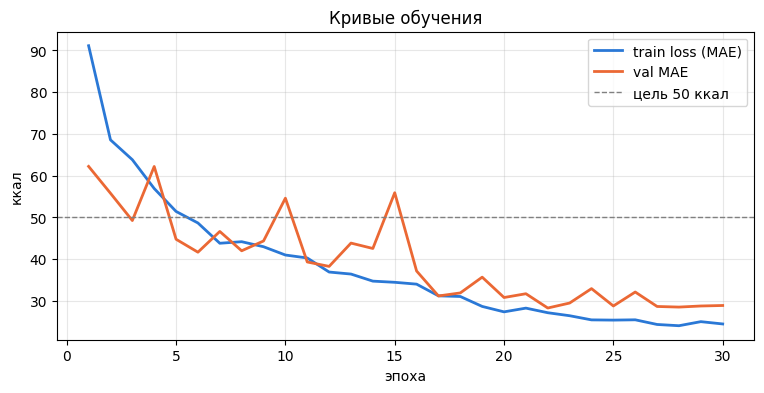

,epoch,train_loss,val_mae,val_rmse
0,1,91.12,62.19,99.65
1,2,68.55,55.76,82.94
2,3,63.79,49.21,75.43
3,4,56.89,62.17,95.94
4,5,51.39,44.73,72.12
5,6,48.63,41.62,64.89
6,7,43.77,46.60,72.57
7,8,44.14,41.96,65.73
8,9,42.93,44.31,71.08
9,10,40.95,54.57,87.18


In [11]:
history_df = pd.DataFrame(history)

fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(history_df["epoch"], history_df["train_loss"], color="#2a78d6", linewidth=2, label="train loss (MAE)")
ax.plot(history_df["epoch"], history_df["val_mae"], color="#eb6834", linewidth=2, label="val MAE")
ax.axhline(50, color="gray", linestyle="--", linewidth=1, label="цель 50 ккал")
ax.set(xlabel="эпоха", ylabel="ккал", title="Кривые обучения")
ax.grid(alpha=0.3)
ax.legend()
plt.show()

history_df.round(2)

К концу обучения скачки val MAE затихают благодаря cosine scheduler, train и val идут близко друг к другу без признаков переобучения, а лучший val MAE = 28.24 получился на 22-й эпохе.

## 3. Проверка на тестовой выборке

In [12]:
from transformers import AutoTokenizer

from scripts.utils import MultimodalModel, evaluate, get_dataloaders

device = torch.device(Config.DEVICE if torch.cuda.is_available() else "cpu")
best_model = MultimodalModel(Config).to(device)
best_model.load_state_dict(torch.load(Config.SAVE_PATH, map_location=device))

tokenizer = AutoTokenizer.from_pretrained(Config.TEXT_MODEL_NAME)
_, _, test_loader = get_dataloaders(Config, tokenizer)

test_metrics = evaluate(best_model, test_loader, Config, device)
print(f"Test MAE {test_metrics['mae']:.2f} | Test RMSE {test_metrics['rmse']:.2f}")

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: bert-base-uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Test MAE 38.63 | Test RMSE 67.36
Цель MAE < 50 достигнута


Цель MAE < 50 достигнута.

## 4. Сохранение артефакта

In [13]:
from google.colab import drive

drive.mount("/content/drive")
save_dir = "/content/drive/MyDrive/nutrition_models"
os.makedirs(save_dir, exist_ok=True)
shutil.copy(Config.SAVE_PATH, save_dir)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Артефакт скопирован в /content/drive/MyDrive/nutrition_models
